In [ ]:
# Import necessary libraries
import pandas as pd 
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes 
import GaussianNB
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap


In [214]:
# Load the data
data = pd.read_csv(r"D:\Ruchitha\Data_Science_PPT\water_potability.csv", encoding='latin1')

# Display the first few rows of the data
data.head()




,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.8904555,20791.31898,7.300211873,368.516441,564.3086542,10.37978308,86.99097046,2.963135381,0
1,3.716080075,129.4229205,18630.05786,6.635245884,NaN,592.8853591,15.18001312,56.32907628,4.500656275,0
2,8.099124189,224.2362594,19909.54173,9.275883603,NaN,418.6062131,16.86863693,66.42009251,3.05593375,0
3,8.316765884,214.3733941,22018.41744,8.059332377,356.886136,363.2665162,18.4365245,100.3416744,4.628770537,0
4,9.092223456,181.1015092,17978.98634,6.546599974,310.135738,398.4108134,11.55827944,31.99799273,4.075075425,0


In [216]:
# Rows and columns count
print(data.shape)  # Output: (number of rows, number of columns)


(3276, 10)


In [217]:
# Check for missing values
missing_values = data.isnull().sum()
print("Missing Values in Each Column:\n", missing_values)


Missing Values in Each Column:
 ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64


In [218]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   object 
 1   Hardness         3276 non-null   object 
 2   Solids           3276 non-null   object 
 3   Chloramines      3276 non-null   object 
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   object 
 6   Organic_carbon   3276 non-null   object 
 7   Trihalomethanes  3114 non-null   object 
 8   Turbidity        3276 non-null   object 
 9   Potability       3276 non-null   int64  
dtypes: float64(1), int64(1), object(8)
memory usage: 256.1+ KB


In [220]:
# Step 1: Convert object types to numeric using pd.to_numeric
for column in data.select_dtypes(include=['object']).columns:
    data[column] = pd.to_numeric(data[column], errors='coerce')

# Step 2: Fill missing values with the median for each column
for column in data.columns:
    if data[column].isnull().sum() > 0:
        data[column] = data[column].fillna(data[column].median())

# Step 3: Check the updated data types
print("\nUpdated Data Types:\n", data.dtypes)



Updated Data Types:
 ph                 float64
Hardness           float64
Solids             float64
Chloramines        float64
Sulfate            float64
Conductivity       float64
Organic_carbon     float64
Trihalomethanes    float64
Turbidity          float64
Potability           int64
dtype: object


In [222]:
data.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
3271    False
3272    False
3273    False
3274    False
3275    False
Length: 3276, dtype: bool

In [225]:
data.duplicated().sum()

0

In [226]:
print("The null value count after treatment")
data.isnull().sum()

The null value count after treatment


ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

In [229]:
data.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.035894,204.890456,20791.31898,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.05786,6.635246,333.073546,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.54173,9.275884,333.073546,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.41744,8.059332,356.886136,363.266516,18.436525,100.341674,4.628771,0
4,9.092223,181.101509,17978.98634,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [230]:
def count_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    return len(outliers)


In [233]:
outliers_count = {}

for column in data.columns:
    if column != 'Potability':
        num_outliers = count_outliers(data[column])
        outliers_count[column] = num_outliers

print("Number of outliers in each column:")
for column, count in outliers_count.items():
    print(f'{column}: {count}')


Number of outliers in each column:
ph: 142
Hardness: 83
Solids: 47
Chloramines: 61
Sulfate: 264
Conductivity: 11
Organic_carbon: 34
Trihalomethanes: 54
Turbidity: 19


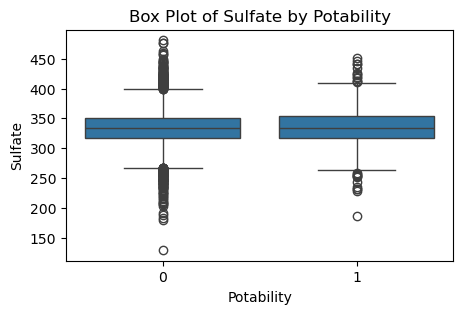

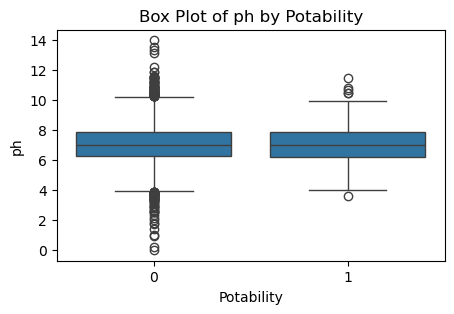

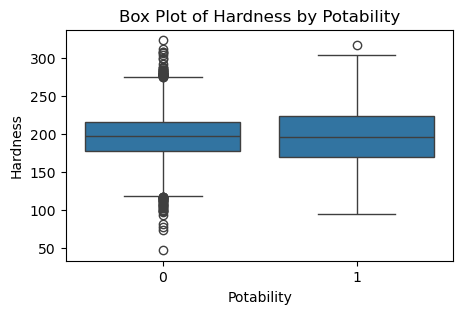

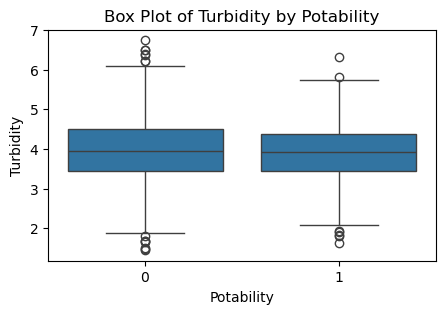

In [234]:
top_3_outlier_columns = ['Sulfate', 'ph', 'Hardness', 'Turbidity'] 

# Visualize outliers using box plots 
for column in top_3_outlier_columns: 
    plt.figure(figsize=(5, 3))  # Reduced figure size
    sns.boxplot(x='Potability', y=column, data=data) 
    plt.title(f'Box Plot of {column} by Potability') 
    plt.show()


In [239]:
# Handle outliers if necessary, e.g., using IQR method
for column in data.columns:
    if column != 'Potability':
        Q1 = data[column].quantile(0.25)
        Q3 = data[column].quantile(0.75)
        IQR = Q3 - Q1
        outliers = (data[column] < (Q1 - 1.5 * IQR)) | (data[column] > (Q3 + 1.5 * IQR))
        data = data[~outliers]


In [240]:
# Function to count outliers in a series
def count_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    return len(outliers)

# Dictionary to hold the count of outliers for each column
outliers_count = {}

# Count outliers in each column (excluding 'Potability')
for column in data.columns:
    if column != 'Potability':
        num_outliers = count_outliers(data[column])
        outliers_count[column] = num_outliers

# Print the number of outliers in each column
print("Number of outliers in each column after handling:")
for column, count in outliers_count.items():
    print(f'{column}: {count}')


Number of outliers in each column after handling:
ph: 52
Hardness: 23
Solids: 5
Chloramines: 13
Sulfate: 106
Conductivity: 0
Organic_carbon: 3
Trihalomethanes: 6
Turbidity: 1


In [241]:
# Check for class imbalance
potability_counts = data['Potability'].value_counts()
print("Potability Class Distribution:\n", potability_counts)



Potability Class Distribution:
 Potability
0    2383
1     267
Name: count, dtype: int64


In [242]:
 # Balance the data using SMOTE
X = data.drop('Potability', axis=1)
y = data['Potability']

sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X, y)


In [243]:
y.value_counts()

Potability
0    2383
1     267
Name: count, dtype: int64

In [244]:
y_res.value_counts()

Potability
0    2383
1    2383
Name: count, dtype: int64

In [246]:
X.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
0,7.035894,204.890456,20791.31898,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135
2,8.099124,224.236259,19909.54173,9.275884,333.073546,418.606213,16.868637,66.420093,3.055934
3,8.316766,214.373394,22018.41744,8.059332,356.886136,363.266516,18.436525,100.341674,4.628771
4,9.092223,181.101509,17978.98634,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075
5,5.584087,188.313324,28748.68774,7.544869,326.678363,280.467916,8.399735,54.917862,2.559708


In [248]:
X_res

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
0,7.035894,204.890456,20791.318980,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135
1,8.099124,224.236259,19909.541730,9.275884,333.073546,418.606213,16.868637,66.420093,3.055934
2,8.316766,214.373394,22018.417440,8.059332,356.886136,363.266516,18.436525,100.341674,4.628771
3,9.092223,181.101509,17978.986340,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075
4,5.584087,188.313324,28748.687740,7.544869,326.678363,280.467916,8.399735,54.917862,2.559708
...,...,...,...,...,...,...,...,...,...
4761,7.289567,185.822852,31026.678877,7.599820,330.482374,441.989646,17.044780,76.366813,4.700043
4762,6.804642,221.318700,8644.941228,6.371209,339.735032,413.267572,9.933766,65.346838,3.411399
4763,8.401278,196.806914,26987.517731,7.487324,333.073546,590.144143,12.673872,62.872386,3.261511
4764,6.454082,228.752422,7534.971014,5.972614,367.716537,289.370154,13.370519,66.915342,3.544900


In [254]:
# Scale the data
scaler = StandardScaler()
X_res_scaled = scaler.fit_transform(X_res)


In [257]:
X_res_scaled

array([[-0.01507181,  0.27520429, -0.07483641, ..., -1.2675782 ,
         1.53130183, -1.38894728],
       [ 0.94060241,  0.9677607 , -0.1804509 , ...,  0.88215877,
         0.03048818, -1.25570303],
       [ 1.13622764,  0.61468204,  0.07213878, ...,  1.40159502,
         2.50534479,  1.00264979],
       ...,
       [ 1.21219092, -0.01417673,  0.66731064, ..., -0.50755369,
        -0.22834603, -0.96052624],
       [-0.53802837,  1.12943388, -1.6626098 , ..., -0.27675681,
         0.06662065, -0.55362288],
       [ 0.00633968,  0.50691908, -0.56497867, ...,  1.38255152,
         1.80100316, -0.13315693]])

In [259]:
X_res_scaled_df = pd.DataFrame(X_res_scaled, columns=X_res.columns)
# Adjust column names as necessary # Display the first few rows of the DataFrame 
X_res_scaled_df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
0,-0.015072,0.275204,-0.074836,0.114105,1.430907,1.838320,-1.267578,1.531302,-1.388947
1,0.940602,0.967761,-0.180451,1.728490,-0.029003,-0.110392,0.882159,0.030488,-1.255703
2,1.136228,0.614682,0.072139,0.734407,0.951849,-0.850538,1.401595,2.505345,1.002650
3,1.833241,-0.576411,-0.411682,-0.501696,-0.973822,-0.380497,-0.877146,-2.480885,0.207628
4,-1.320016,-0.318237,0.878254,0.314022,-0.292423,-1.957936,-1.923562,-0.808694,-1.968207


In [262]:
y_res.value_counts()

Potability
0    2383
1    2383
Name: count, dtype: int64

In [264]:
# Statistical Summary
data.describe()



,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2650.000000,2650.000000,2650.000000,2650.000000,2650.000000,2650.000000,2650.000000,2650.000000,2650.000000,2650.000000
mean,7.072672,196.935023,21456.849417,7.111591,333.625277,425.715456,14.324153,66.485279,3.963213,0.100755
std,1.214437,28.230306,7863.530404,1.407711,26.253474,79.857325,3.171364,14.985032,0.761731,0.301060
min,3.902476,118.988579,320.942611,3.239580,268.646941,201.619737,5.537059,26.140863,1.872573,0.000000
25%,6.354205,179.010144,15614.235043,6.192655,319.536122,365.724484,12.168441,56.951528,3.439497,0.000000
50%,7.035894,197.471398,20595.162475,7.118162,333.073546,421.180253,14.225917,66.621027,3.949875,0.000000
75%,7.795447,215.611390,26701.330505,8.042706,347.921235,481.180953,16.535959,76.685256,4.496106,0.000000
max,10.252816,275.679780,44376.187380,10.999995,399.617217,652.537592,23.135952,107.306343,6.083772,1.000000


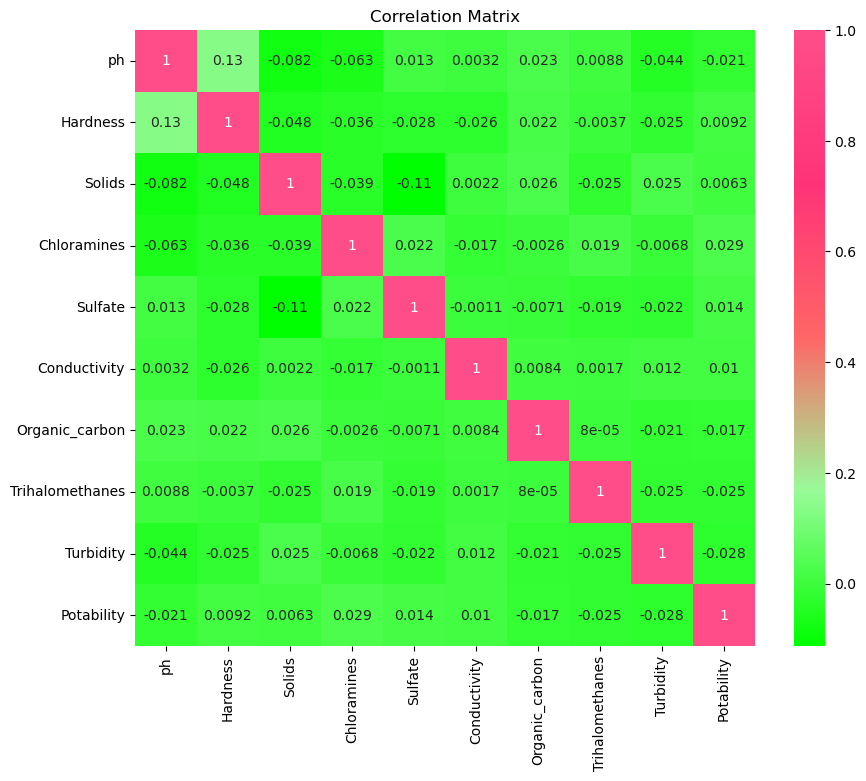

In [266]:
# Correlation matrix heatmap
green_balanced_pink_colors = ['#00FF00', '#98FB98', '#FF6666', '#FF3378', '#FF4D89']
green_balanced_pink_cmap = LinearSegmentedColormap.from_list("green_balanced_pink", green_balanced_pink_colors)

plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), annot=True, cmap=green_balanced_pink_cmap)
plt.title('Correlation Matrix')
plt.show()


           Feature  Importance
3      Chloramines    0.142785
0               ph    0.134429
2           Solids    0.123854
4          Sulfate    0.121087
1         Hardness    0.110463
8        Turbidity    0.096671
7  Trihalomethanes    0.094091
5     Conductivity    0.089873
6   Organic_carbon    0.086748


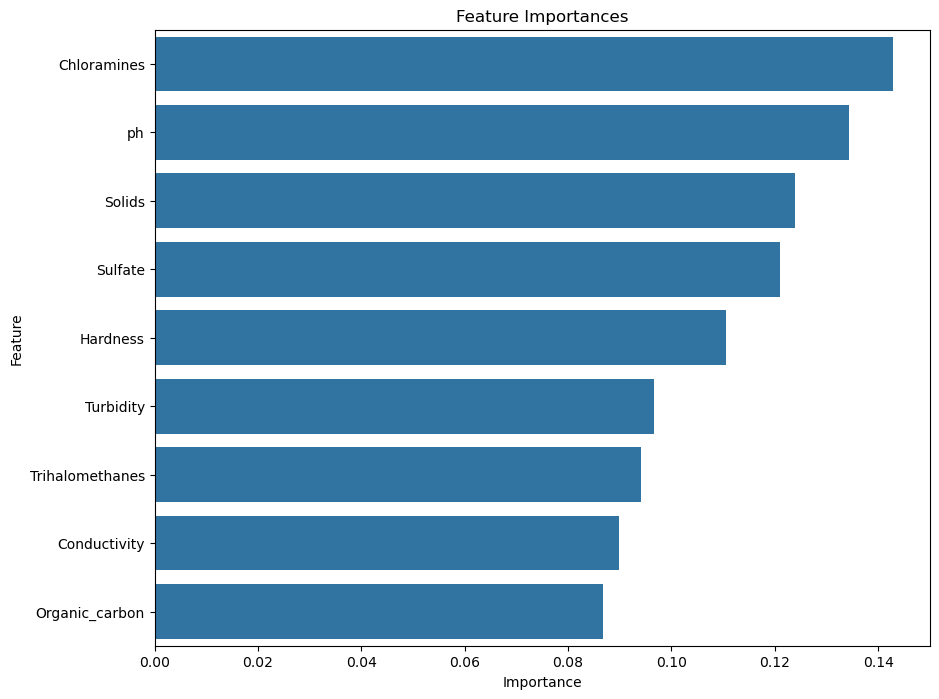

In [269]:
# Feature importances using Random Forest
model = RandomForestClassifier(random_state=42)
model.fit(X_res_scaled, y_res)

importances = model.feature_importances_
feature_importances = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_importances = feature_importances.sort_values(by='Importance', ascending=False)
print(feature_importances)

plt.figure(figsize=(10,8))
sns.barplot(x='Importance', y='Feature', data=feature_importances)
plt.title('Feature Importances')
plt.show()


<Figure size 800x800 with 0 Axes>

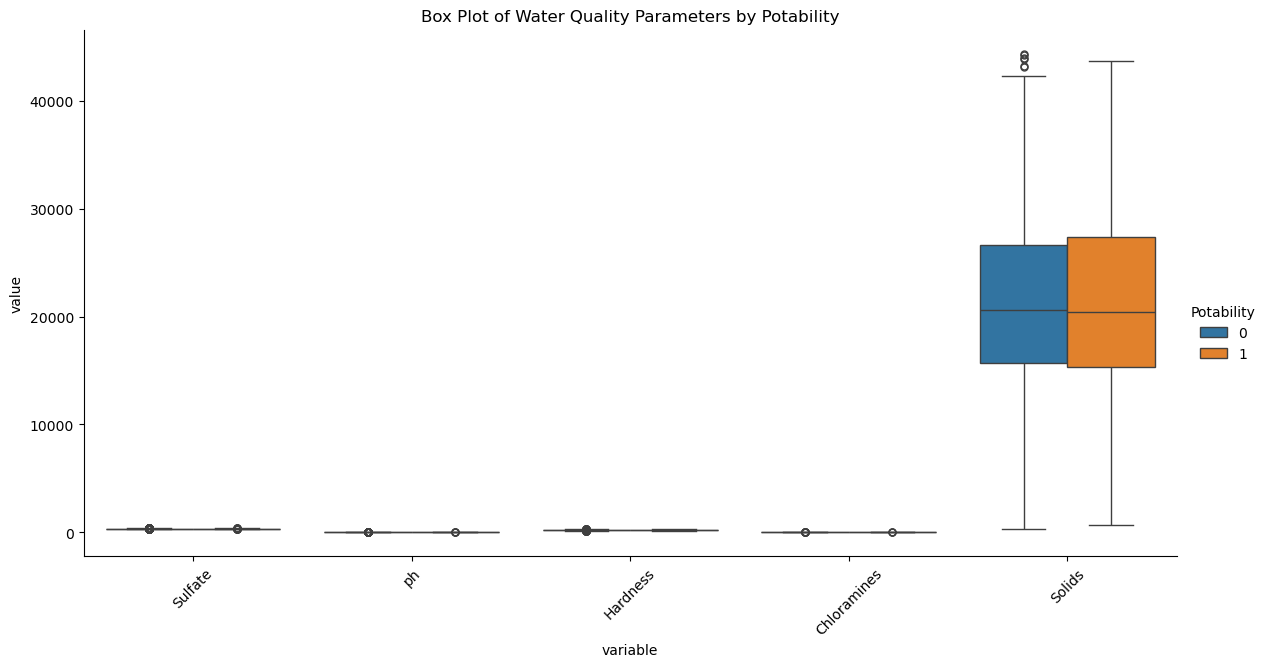

In [270]:
# # Cell 10: Pair plots for selected features
# features = ['Sulfate', 'ph', 'Hardness', 'Chloramines', 'Solids']

# for feature in features:
#     sns.pairplot(data, x_vars=[feature], y_vars=['Potability'], hue='Potability')
#     plt.title(f'Pair Plot of {feature} vs Potability')
#     plt.show()



# Melt the dataframe to long-form for seaborn's catplot
melted_data = pd.melt(data, id_vars='Potability', value_vars=['Sulfate', 'ph', 'Hardness', 'Chloramines', 'Solids'])

# Create a catplot
plt.figure(figsize=(8, 8))
sns.catplot(x='variable', y='value', hue='Potability', kind='box', data=melted_data, height=6, aspect=2)
plt.title('Box Plot of Water Quality Parameters by Potability')
plt.xticks(rotation=45)
plt.show()



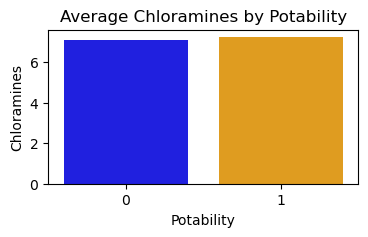

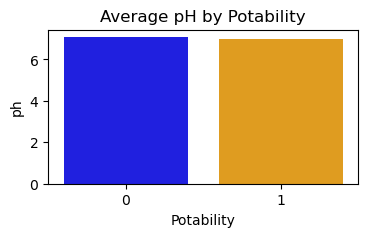

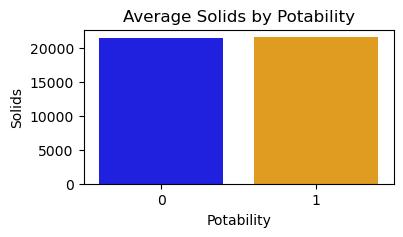

In [271]:
# Visualizations for Potability
data['Potability'] = data['Potability'].astype(str)

# Barchart for Chloramines by Potability
plt.figure(figsize=(4, 2))
sns.barplot(x='Potability', y='Chloramines', data=data, errorbar=None, palette={'0': 'blue', '1': 'orange'}, hue='Potability', dodge=False)
plt.title('Average Chloramines by Potability')
plt.show()

# Barchart for pH by Potability
plt.figure(figsize=(4, 2))
sns.barplot(x='Potability', y='ph', data=data, errorbar=None, palette={'0': 'blue', '1': 'orange'}, hue='Potability', dodge=False)
plt.title('Average pH by Potability')
plt.show()

# Barchart for Solids by Potability
plt.figure(figsize=(4, 2))
sns.barplot(x='Potability', y='Solids', data=data, errorbar=None, palette={'0': 'blue', '1': 'orange'}, hue='Potability', dodge=False)
plt.title('Average Solids by Potability')
plt.show()


In [273]:
#  Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X_res_scaled, y_res, test_size=0.3, random_state=42)


In [274]:
import pandas as pd

# Convert X_train and X_test to DataFrames
X_train_df = pd.DataFrame(X_train, columns=X_res.columns)
X_test_df = pd.DataFrame(X_test, columns=X_res.columns)

# Convert y_train and y_test to DataFrames
y_train_df = pd.DataFrame(y_train, columns=['Potability'])
y_test_df = pd.DataFrame(y_test, columns=['Potability'])

# Display the first few rows of each DataFrame
print("X_train DataFrame:")
print(X_train_df.head())

print("\nX_test DataFrame:")
print(X_test_df.head())

print("\ny_train DataFrame:")
print(y_train_df.head())

print("\ny_test DataFrame:")
print(y_test_df.head())


X_train DataFrame:
         ph  Hardness    Solids  Chloramines   Sulfate  Conductivity  \
0  0.639507 -0.396310  0.540177     0.695081 -0.029003     -0.370855   
1 -0.473166  0.456899 -1.796881    -0.482578  1.429554     -0.602396   
2 -0.012196 -0.628544  0.887677    -1.809961  2.311264      2.227355   
3  0.801065  0.523150  1.276204     0.497342 -1.789325     -0.983348   
4 -0.848136 -0.195009  0.651313     1.555854 -0.888712     -0.686287   

   Organic_carbon  Trihalomethanes  Turbidity  
0        2.862616        -2.244086   0.250851  
1        0.776728         1.125042   0.043792  
2       -0.704564        -0.557306   0.625397  
3        1.214553         0.911290   0.260203  
4        0.433383         0.568160   1.364958  

X_test DataFrame:
         ph  Hardness    Solids  Chloramines   Sulfate  Conductivity  \
0 -0.378080  0.159913  0.328796     0.656937  1.476429     -1.069963   
1 -2.406902 -1.896110 -0.482916     1.420065 -0.029003     -0.328866   
2 -0.211276  0.792388  0.

In [285]:

param_dist_dt = {
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
random_search_dt = RandomizedSearchCV(estimator=DecisionTreeClassifier(random_state=42), param_distributions=param_dist_dt, n_iter=50, cv=5, scoring='accuracy', random_state=42, verbose=2)
random_search_dt.fit(X_train, y_train)
best_dt_model = random_search_dt.best_estimator_
print("Best hyperparameters for Decision Tree: ", random_search_dt.best_params_)


Fitting 5 folds for each of 36 candidates, totalling 180 fits


C:\Users\Asus\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:307: UserWarning: The total space of parameters 36 is smaller than n_iter=50. Running 36 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=5; total time=   0.0s
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=5; total time=   0.1s
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=5; total time=   0.0s
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=5; total time=   0.0s
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=5; total time=   0.0s
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=10; total time=   0.0s
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=1

In [287]:

param_dist_nb = {
    'var_smoothing': np.logspace(0, -9, num=100)
}
random_search_nb = RandomizedSearchCV(estimator=GaussianNB(), param_distributions=param_dist_nb, n_iter=50, cv=5, scoring='accuracy', random_state=42, verbose=2)
random_search_nb.fit(X_train, y_train)
best_nb_model = random_search_nb.best_estimator_
print("Best hyperparameters for Naive Bayes: ", random_search_nb.best_params_)


Fitting 5 folds for each of 50 candidates, totalling 250 fits
[CV] END ................var_smoothing=2.848035868435799e-08; total time=   0.0s
[CV] END ................var_smoothing=2.848035868435799e-08; total time=   0.0s
[CV] END ................var_smoothing=2.848035868435799e-08; total time=   0.0s
[CV] END ................var_smoothing=2.848035868435799e-08; total time=   0.0s
[CV] END ................var_smoothing=2.848035868435799e-08; total time=   0.0s
[CV] END ...............var_smoothing=1.5199110829529332e-05; total time=   0.0s
[CV] END ...............var_smoothing=1.5199110829529332e-05; total time=   0.0s
[CV] END ...............var_smoothing=1.5199110829529332e-05; total time=   0.0s
[CV] END ...............var_smoothing=1.5199110829529332e-05; total time=   0.0s
[CV] END ...............var_smoothing=1.5199110829529332e-05; total time=   0.0s
[CV] END ...............var_smoothing=4.3287612810830526e-07; total time=   0.0s
[CV] END ...............var_smoothing=4.3287612

In [289]:

param_dist_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}
random_search_rf = RandomizedSearchCV(estimator=RandomForestClassifier(random_state=42), param_distributions=param_dist_rf, n_iter=50, cv=5, scoring='accuracy', random_state=42, verbose=2)
random_search_rf.fit(X_train, y_train)
best_rf_model = random_search_rf.best_estimator_
print("Best hyperparameters for Random Forest: ", random_search_rf.best_params_)


Fitting 5 folds for each of 50 candidates, totalling 250 fits
[CV] END bootstrap=False, max_depth=30, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=   2.2s
[CV] END bootstrap=False, max_depth=30, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=   2.5s
[CV] END bootstrap=False, max_depth=30, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=   2.2s
[CV] END bootstrap=False, max_depth=30, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=   2.3s
[CV] END bootstrap=False, max_depth=30, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=   2.1s
[CV] END bootstrap=False, max_depth=30, min_samples_leaf=4, min_samples_split=10, n_estimators=50; total time=   2.3s
[CV] END bootstrap=False, max_depth=30, min_samples_leaf=4, min_samples_split=10, n_estimators=50; total time=   2.0s
[CV] END bootstrap=False, max_depth=30, min_samples_leaf=4, min_samples_split=10, n_estimators=50; total time=   2.0s

In [ ]:
# # Train and evaluate each model
# for model_name, model in models.items():
#     # Fit the model
#     model.fit(X_train, y_train)
#     y_pred = model.predict(X_test)
    
#     # Accuracy
#     accuracy = accuracy_score(y_test, y_pred)
#     print(f'{model_name} Accuracy: {accuracy}')
    
#     # Confusion Matrix
#     cm = confusion_matrix(y_test, y_pred)
#     print(f'{model_name} Confusion Matrix:\n', cm)
    
#     # Classification Report
#     cr = classification_report(y_test, y_pred)
#     print(f'{model_name} Classification Report:\n', cr)
    
#     # ROC-AUC Score
#     roc_auc = roc_auc_score(y_test, y_pred)
#     print(f'{model_name} ROC-AUC Score: {roc_auc}')
    
#     # Cross-validation score
#     cv_scores = cross_val_score(model.best_estimator_, X_res, y_res, cv=5)
#     print(f'{model_name} Cross-Validation Scores: {cv_scores}')
#     print(f'{model_name} Average Cross-Validation Score: {np.mean(cv_scores)}\n')


In [303]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score
from sklearn.model_selection import cross_val_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dictionary to store accuracy scores
accuracy_scores = {}

# Function to evaluate a model and store its accuracy
def evaluate_model(model, model_name):
    # Fit the model
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Accuracy
    accuracy = accuracy_score(y_test, y_pred)
    accuracy_scores[model_name] = accuracy
    print(f'{model_name} Accuracy: {accuracy}')

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    print(f'{model_name} Confusion Matrix:\n', cm)

    # Classification Report
    cr = classification_report(y_test, y_pred)
    print(f'{model_name} Classification Report:\n', cr)

    # ROC-AUC Score
    roc_auc = roc_auc_score(y_test, y_pred)
    print(f'{model_name} ROC-AUC Score: {roc_auc}')

    # Cross-validation score
    cv_scores = cross_val_score(model, X_res, y_res, cv=5)
    print(f'{model_name} Cross-Validation Scores: {cv_scores}')
    print(f'{model_name} Average Cross-Validation Score: {np.mean(cv_scores)}\n')

# Evaluate Decision Tree
evaluate_model(best_dt_model, 'Decision Tree')

# Evaluate Naive Bayes
evaluate_model(best_nb_model, 'Naive Bayes')

# Evaluate Random Forest
evaluate_model(best_rf_model, 'Random Forest')



Decision Tree Accuracy: 0.7797202797202797
Decision Tree Confusion Matrix:
 [[540 179]
 [136 575]]
Decision Tree Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.75      0.77       719
           1       0.76      0.81      0.78       711

    accuracy                           0.78      1430
   macro avg       0.78      0.78      0.78      1430
weighted avg       0.78      0.78      0.78      1430

Decision Tree ROC-AUC Score: 0.7798816139778447
Decision Tree Cross-Validation Scores: [0.76624738 0.7838405  0.79328437 0.79013641 0.76915005]
Decision Tree Average Cross-Validation Score: 0.7805317424177429

Naive Bayes Accuracy: 0.6531468531468532
Naive Bayes Confusion Matrix:
 [[409 310]
 [186 525]]
Naive Bayes Classification Report:
               precision    recall  f1-score   support

           0       0.69      0.57      0.62       719
           1       0.63      0.74      0.68       711

    accuracy                   

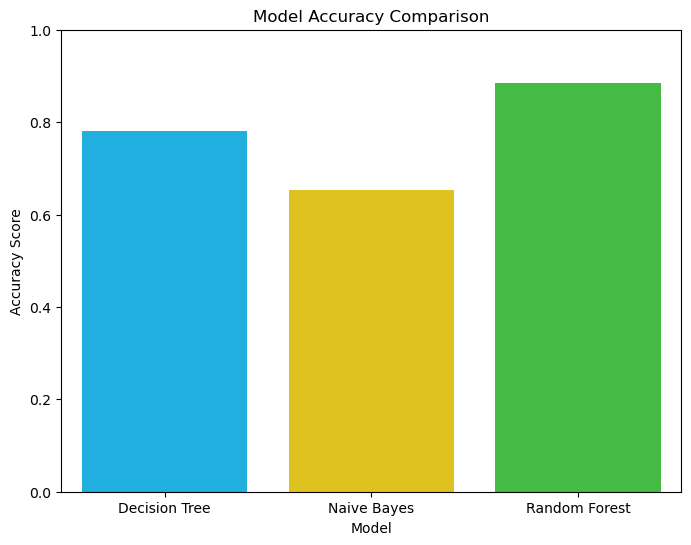

In [313]:
# Create a DataFrame for the accuracy scores 
accuracy_df = pd.DataFrame(list(accuracy_scores.items()), columns=['Model', 'Accuracy']) 
# Define a custom bright color palette excluding red 
bright_palette = ['#00BFFF', '#FFD700', '#32CD32'] # Bright Blue, Bright Yellow, Bright Green 
# Create a bar plot for model accuracy comparison with bright colors 
plt.figure(figsize=(8, 6)) 
sns.barplot(x='Model', y='Accuracy', data=accuracy_df, hue='Model', palette=bright_palette, legend=False)
plt.title('Model Accuracy Comparison')
plt.ylim(0, 1)
# Ensuring the y-axis ranges from 0 to 1 for better comparison 
plt.ylabel('Accuracy Score') 
plt.xlabel('Model')
plt.show()